# Stochastic Processes and White Noise

This notebook accompanies the note [stochastic processes and white noise](../../notes/time_series/stochastic_processes_and_white_noise.md). A stochastic process $\{X_t\}$ is a family of random variables; the data we see is one sample path. White noise is the reference process for unstructured shocks, and the note stresses that *uncorrelated* is weaker than *independent*.

We verify:

1. paths versus the process (ensemble means and variances);
2. the random walk calculations $\mathrm{Var}(X_{100})=100$ and, for $\sigma^2=4$, $\mathrm{Var}(X_{25})=100$;
3. the counterexample $X_t=Z_tZ_{t-1}$ that is white noise but dependent;
4. a martingale-difference sequence with predictable variance (ARCH-type);
5. the linear-process variance formula and residual use.

## 1. One path versus the process

For fixed $t$, $X_t$ is a random variable; the observed $x_t$ is a single draw. Averaging across many independent paths estimates the mean function $\mu_t$ and the variance function, while an average along one path is a different object. Here the process is Gaussian white noise with $\sigma^2=1$ and the process is a random walk built from it.

t= 10  white noise: mean=-0.010 var=0.981   | random walk: mean= 0.105 var=  10.47 (theory 10)
t= 50  white noise: mean=-0.004 var=0.993   | random walk: mean= 0.152 var=  50.22 (theory 50)
t=100  white noise: mean= 0.012 var=0.965   | random walk: mean= 0.079 var= 100.28 (theory 100)
t=150  white noise: mean=-0.009 var=0.982   | random walk: mean= 0.037 var= 147.84 (theory 150)


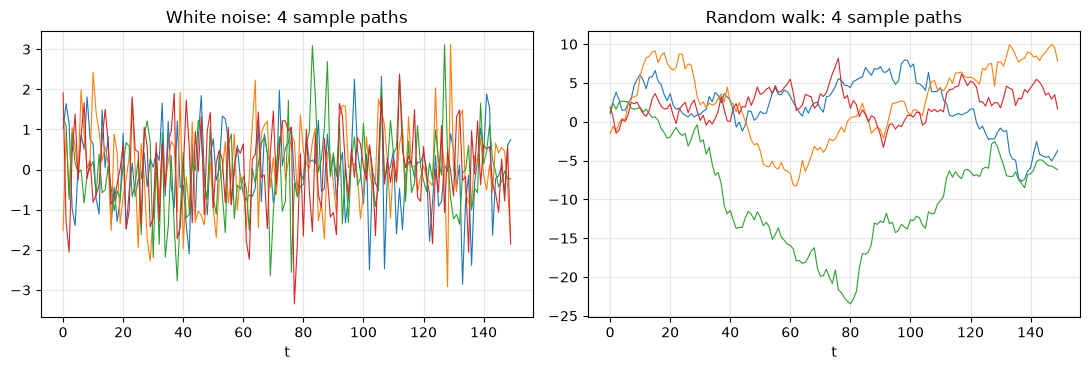

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

rng = np.random.default_rng(2024)
n_paths, T = 4000, 150
eps = rng.normal(0, 1, (n_paths, T))         # white noise, sigma^2 = 1
walk = eps.cumsum(axis=1)                      # X_0 = 0

for t in (10, 50, 100, 150):
    print(f"t={t:3d}  white noise: mean={eps[:, t-1].mean():6.3f} var={eps[:, t-1].var():5.3f}"
          f"   | random walk: mean={walk[:, t-1].mean():6.3f} var={walk[:, t-1].var():7.2f} (theory {t})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
ax[0].plot(eps[:4].T, lw=0.8); ax[0].set_title("White noise: 4 sample paths")
ax[1].plot(walk[:4].T, lw=0.8); ax[1].set_title("Random walk: 4 sample paths")
for a in ax: a.grid(alpha=0.3); a.set_xlabel("t")
plt.tight_layout(); plt.show()

Each column of the ensemble has mean about $0$, but the cross-path variance is constant ($\approx1$) for white noise and equals $t$ for the random walk. In particular $\mathrm{Var}(X_{100})\approx100$, matching the worked calculation $\mathrm{Var}(X_{100})=100$: shocks have constant variance while their accumulated sum does not.

## 2. Variance with $\sigma^2=4$ after 25 steps

The student guide states that with $\sigma^2=4$ the conditional variance after 25 steps is $25\cdot 4=100$. We check this and also the distribution of $X_{25}$: it should be $N(0,100)$ for Gaussian shocks.

Var(X_25) theory: 100.0   simulated: 100.5
P(|X_25| < 10) theory: 0.6827   simulated: 0.6825


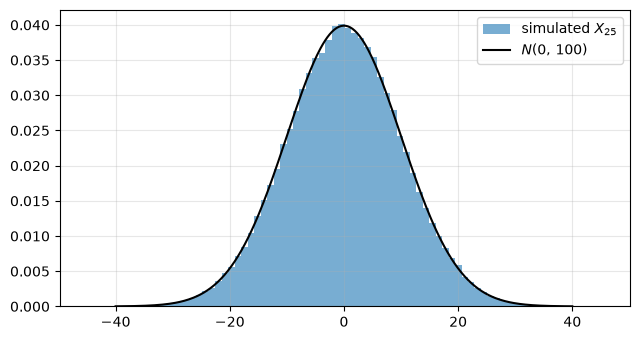

In [2]:
from scipy import stats
sigma = 2.0
x25 = rng.normal(0, sigma, (200_000, 25)).sum(axis=1)
print("Var(X_25) theory:", 25 * sigma**2, "  simulated:", round(x25.var(), 2))
print("P(|X_25| < 10) theory:", round(stats.norm.cdf(1) - stats.norm.cdf(-1), 4),
      "  simulated:", round(np.mean(np.abs(x25) < 10), 4))

plt.figure(figsize=(6.5, 3.5))
plt.hist(x25, bins=80, density=True, alpha=0.6, label="simulated $X_{25}$")
g = np.linspace(-40, 40, 400)
plt.plot(g, stats.norm.pdf(g, 0, 10), "k", label=r"$N(0,\,100)$")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

The simulated variance is close to $100$ and the histogram sits on the $N(0,100)$ density. Uncertainty about the level accumulates from one step to the next even though each increment has the same variance.

## 3. White noise without independence: $X_t = Z_tZ_{t-1}$

With $Z_t$ iid standard normal, $\mathrm{Cov}(X_t,X_{t-1})=E[Z_tZ_{t-1}^2Z_{t-2}]=0$ and all other lags are uncorrelated, so $X_t$ is weak white noise. But $X_t$ and $X_{t-1}$ share $Z_{t-1}$, so $X_t^2$ and $X_{t-1}^2$ are dependent. For standard normal $Z$:
$\mathrm{Cov}(X_t^2,X_{t-1}^2)=3-1=2$ and $\mathrm{Var}(X_t^2)=9-1=8$, so $\mathrm{Corr}(X_t^2,X_{t-1}^2)=0.25$.

In [3]:
n = 200_000
z = rng.normal(size=n + 1)
x = z[1:] * z[:-1]

a_x  = acf(x, nlags=5)
a_x2 = acf(x**2, nlags=5)
print("ACF of X_t   lags 1-5:", np.round(a_x[1:], 3))
print("ACF of X_t^2 lags 1-5:", np.round(a_x2[1:], 3), "  (theory lag 1: 0.25, later lags 0)")
print("variance of X_t:", round(x.var(), 3), "(theory 1)")

lb = acorr_ljungbox(x, lags=[10], return_df=True)
lb2 = acorr_ljungbox(x**2, lags=[10], return_df=True)
print("Ljung-Box p-value, X_t   :", float(lb["lb_pvalue"].iloc[0]))
print("Ljung-Box p-value, X_t^2 :", float(lb2["lb_pvalue"].iloc[0]))

ACF of X_t   lags 1-5: [ 0.005 -0.002 -0.002  0.002 -0.001]
ACF of X_t^2 lags 1-5: [ 0.248  0.002  0.    -0.001 -0.001]   (theory lag 1: 0.25, later lags 0)
variance of X_t: 1.01 (theory 1)


Ljung-Box p-value, X_t   : 0.47020722214346755
Ljung-Box p-value, X_t^2 : 0.0


The levels look like white noise (ACF near zero, large Ljung-Box p-value), but the squares have lag-1 correlation near $0.25$ and a tiny p-value. An ACF close to zero does not establish independence; checking squared values is a cheap way to see nonlinear dependence.

## 4. Martingale differences with time-varying variance

A martingale difference satisfies $E(\varepsilon_t\mid\mathcal F_{t-1})=0$: the conditional mean is unpredictable. It can still have a conditional variance that depends on the past. An ARCH(1) shock $\varepsilon_t=\sqrt{0.2+0.5\varepsilon_{t-1}^2}\,z_t$ is the standard example: it has zero mean, constant unconditional variance $0.2/(1-0.5)=0.4$, no autocorrelation, yet volatility clusters.

mean: 0.0015   variance: 0.375 (theory 0.4)
ACF of e   lags 1-3: [ 0.002 -0.009  0.01 ]
ACF of e^2 lags 1-3: [0.446 0.18  0.066] (lag 1 theory 0.5)


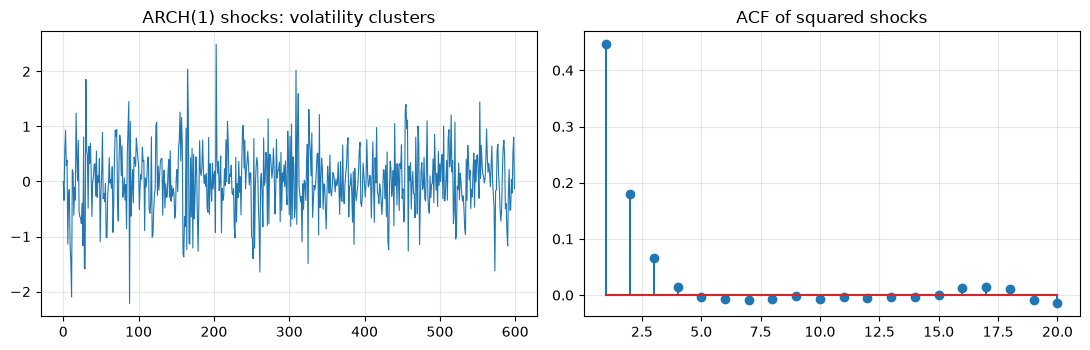

In [4]:
n = 20_000
z = rng.normal(size=n)
e = np.zeros(n)
for t in range(1, n):
    e[t] = np.sqrt(0.2 + 0.5 * e[t - 1] ** 2) * z[t]

print("mean:", round(e.mean(), 4), "  variance:", round(e.var(), 3), "(theory 0.4)")
print("ACF of e   lags 1-3:", np.round(acf(e, nlags=3)[1:], 3))
print("ACF of e^2 lags 1-3:", np.round(acf(e**2, nlags=3)[1:], 3), "(lag 1 theory 0.5)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(e[:600], lw=0.8); ax[0].set_title("ARCH(1) shocks: volatility clusters")
ax[1].stem(range(1, 21), acf(e**2, nlags=20)[1:])
ax[1].set_title("ACF of squared shocks")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The shocks are serially uncorrelated and have a stable unconditional variance, so they are weak white noise, but quiet and turbulent stretches alternate and the squares are positively autocorrelated. Their conditional mean is zero (martingale difference) while their conditional variance is predictable.

## 5. Linear processes and residual use

For $X_t=\sum_{j\ge0}\psi_j\varepsilon_{t-j}$ with uncorrelated innovations, $\mathrm{Var}(X_t)=\sigma_\varepsilon^2\sum_j\psi_j^2$. With $\psi_j=0.6^j$ and $\sigma^2_\varepsilon=1$ this is $1/(1-0.36)=1.5625$, and it is the same process as an AR(1) with $\phi=0.6$.

A good model leaves white-noise residuals. We fit an AR(1) (by least squares) to AR(2) data and to AR(1) data and test the residuals.

sum psi^2 = 1.5625   closed form 1/(1-0.36) = 1.5625
simulated Var(AR(1)) = 1.5502
AR(1) data: phi_hat=0.584, Ljung-Box(10) p-value of AR(1) residuals = 0.9031
AR(2) data: phi_hat=0.417, Ljung-Box(10) p-value of AR(1) residuals = 0.0000


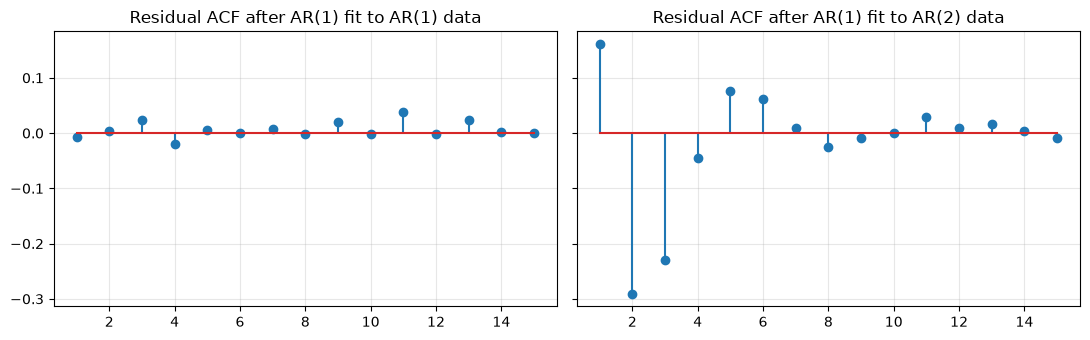

In [5]:
# Linear-process variance
psi = 0.6 ** np.arange(200)
print("sum psi^2 =", round(np.sum(psi**2), 4), "  closed form 1/(1-0.36) =", round(1/(1-0.36), 4))

n = 3000
e = rng.normal(size=n + 200)
ar1 = np.zeros(n + 200); ar2 = np.zeros(n + 200)
for t in range(2, n + 200):
    ar1[t] = 0.6 * ar1[t - 1] + e[t]
    ar2[t] = 0.6 * ar2[t - 1] - 0.4 * ar2[t - 2] + e[t]
ar1, ar2 = ar1[200:], ar2[200:]
print("simulated Var(AR(1)) =", round(ar1.var(), 4))

def ar1_residuals(x):
    phi = np.dot(x[1:], x[:-1]) / np.dot(x[:-1], x[:-1])
    return phi, x[1:] - phi * x[:-1]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, (name, series) in zip(ax, (("AR(1) data", ar1), ("AR(2) data", ar2))):
    phi, res = ar1_residuals(series)
    p = float(acorr_ljungbox(res, lags=[10], return_df=True)["lb_pvalue"].iloc[0])
    print(f"{name}: phi_hat={phi:.3f}, Ljung-Box(10) p-value of AR(1) residuals = {p:.4f}")
    a.stem(range(1, 16), acf(res, nlags=15)[1:])
    a.set_title(f"Residual ACF after AR(1) fit to {name}")
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The summed squared weights reproduce $1.5625$, confirming the linear-process variance formula. Residuals of the correctly specified AR(1) look white, while the AR(1) fitted to AR(2) data leaves clear autocorrelation (and a very small p-value), which signals remaining predictable structure.

**Takeaways.** A path is not the process; weak white noise is only uncorrelated, not independent; a random walk accumulates shocks so its level variance is $t\sigma^2$; and white-noise residuals are a necessary diagnostic, not proof of a complete model.